# Swissquote BBO — overview

Load recent rows from `swissquote.bbo` (ClickHouse) and inspect coverage: row counts, symbols,
platforms, quote quality, price/spread distributions, and basic intraday activity.

Deeper mid/spread time-series work lives in `02_spreads_eda.ipynb`.

**Prerequisites:** `~/.env` with `CLICKHOUSE_HOST`, Python client installed (`pip install -e "../python[databases]"`), and notebook deps (`pip install -r requirements.txt`).


In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from swissquote.clickhouse import ClickHouseConfig, create_client

from ch_utils import enrich_bbo, load_bbo_df, table_overview

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

cfg = ClickHouseConfig.from_env()
client = create_client(cfg)
print(f"Connected to {cfg.host}:{cfg.port} as {cfg.user}")

Connected to 127.0.0.1:9000 as default


In [2]:
overview = table_overview(client)
print(f"Rows (FINAL): {overview['row_count']:,}")
print(f"Ingestion range: {overview['ingestion_min']} → {overview['ingestion_max']}")

symbol_counts = pd.DataFrame(overview["symbol_counts"], columns=["symbol", "rows"])
display(symbol_counts.head(20))

Rows (FINAL): 126,603,084
Ingestion range: 2026-07-05 21:05:13.290000+00:00 → 2026-07-23 22:38:06.745000+00:00


,symbol,rows
0,GBP/AUD,1574577
1,GBP/JPY,1574077
2,GBP/NZD,1573981
3,GBP/SGD,1572542
4,EUR/NZD,1572051
5,GBP/CAD,1568216
6,GBP/CHF,1565704
7,EUR/AUD,1565231
8,CHF/JPY,1563576
9,CHF/SGD,1563334


In [3]:
HOURS = 24
LIMIT = 50_000

df = load_bbo_df(client, hours=HOURS, limit=LIMIT)
df = enrich_bbo(df)
print(f"Loaded {len(df):,} rows from the last {HOURS}h")
df.head()

Loaded 50,000 rows from the last 24h


,ts,symbol,platform,server,spread_profile,bid_price,ask_price,bid_spread,ask_spread,ingestion_time,mid,spread_abs,spread_bps,quote_age_ms
0,2026-07-22 22:38:35.735000+00:00,AUD/CAD,AT,AT,premium,0.98431,0.98457,0.90,0.90,2026-07-22 22:38:38.739000+00:00,0.984440,0.00026,2.641095,3004.0
1,2026-07-22 22:38:35.735000+00:00,AUD/CAD,AT,AT,prime,0.98433,0.98456,0.75,0.75,2026-07-22 22:38:38.739000+00:00,0.984445,0.00023,2.336342,3004.0
2,2026-07-22 22:38:35.735000+00:00,AUD/CAD,AT,AT,standard,0.98430,0.98458,1.00,1.00,2026-07-22 22:38:38.739000+00:00,0.984440,0.00028,2.844257,3004.0
3,2026-07-22 22:38:35.735000+00:00,AUD/CAD,SwissquoteCapitalMarkets,Live7,elite,0.98440,0.98448,0.00,0.00,2026-07-22 22:38:38.739000+00:00,0.984440,0.00008,0.812645,3004.0
4,2026-07-22 22:38:35.735000+00:00,AUD/CAD,SwissquoteCapitalMarkets,Live7,premium,0.98433,0.98456,0.75,0.75,2026-07-22 22:38:38.739000+00:00,0.984445,0.00023,2.336342,3004.0


## Sample window

Numeric summary of the loaded window (`HOURS` / `LIMIT` above), plus missingness and simple quote-quality checks.


In [4]:
price_cols = [
    c
    for c in [
        "bid_price",
        "ask_price",
        "mid",
        "spread_abs",
        "spread_bps",
        "bid_spread",
        "ask_spread",
        "quote_age_ms",
    ]
    if c in df.columns
]
display(df[price_cols].describe().round(4))

print(f"ts range: {df['ts'].min()} → {df['ts'].max()}")
print(
    f"symbols: {df['symbol'].nunique()} | platforms: {df['platform'].nunique()} "
    f"| profiles: {df['spread_profile'].nunique()} | servers: {df['server'].nunique()}"
)


,bid_price,ask_price,mid,spread_abs,spread_bps,bid_spread,ask_spread,quote_age_ms
count,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000
mean,31.0497,31.0729,31.0613,0.0233,3.1981,0.9480,0.9480,2660.2527
std,247.9147,248.0745,247.9946,0.2474,4.6399,2.0242,2.0242,11397.5197
min,0.4712,0.4714,0.4714,0.0000,0.1170,0.0000,0.0000,115.0000
25%,0.8138,0.8140,0.8139,0.0002,1.8390,0.5000,0.5000,782.0000
50%,0.9845,0.9847,0.9846,0.0002,2.3657,0.7500,0.7500,1384.0000
75%,1.2073,1.2077,1.2075,0.0004,3.1942,1.0000,1.0000,2213.0000
max,5811.1500,5814.3700,5812.7000,5.5000,182.0546,50.0000,50.0000,537314.0000


ts range: 2026-07-22 22:38:35.735000+00:00 → 2026-07-23 22:38:06.490000+00:00
symbols: 87 | platforms: 3 | profiles: 4 | servers: 3


In [5]:
missing = df.isna().mean().mul(100).rename("pct_null").to_frame()
missing["nulls"] = df.isna().sum()
if missing["nulls"].sum():
    display(missing.query("nulls > 0"))
else:
    print("No nulls in sample columns.")

quality = pd.Series(
    {
        "rows": len(df),
        "crossed_or_locked (ask <= bid)": int((df["ask_price"] <= df["bid_price"]).sum()),
        "non_positive spread_abs": int((df["spread_abs"] <= 0).sum())
        if "spread_abs" in df.columns
        else None,
        "negative bid_spread": int((df["bid_spread"] < 0).sum())
        if "bid_spread" in df.columns
        else None,
        "negative ask_spread": int((df["ask_spread"] < 0).sum())
        if "ask_spread" in df.columns
        else None,
        "duplicate (ts, symbol, platform, server, spread_profile)": int(
            df.duplicated(
                subset=["ts", "symbol", "platform", "server", "spread_profile"]
            ).sum()
        ),
    }
)
display(quality.to_frame("count"))


No nulls in sample columns.


,count
rows,50000
crossed_or_locked (ask <= bid),0
non_positive spread_abs,0
negative bid_spread,0
negative ask_spread,0
"duplicate (ts, symbol, platform, server, spread_profile)",72


## Coverage in the sample

Row mix by symbol, platform, spread profile, and server.


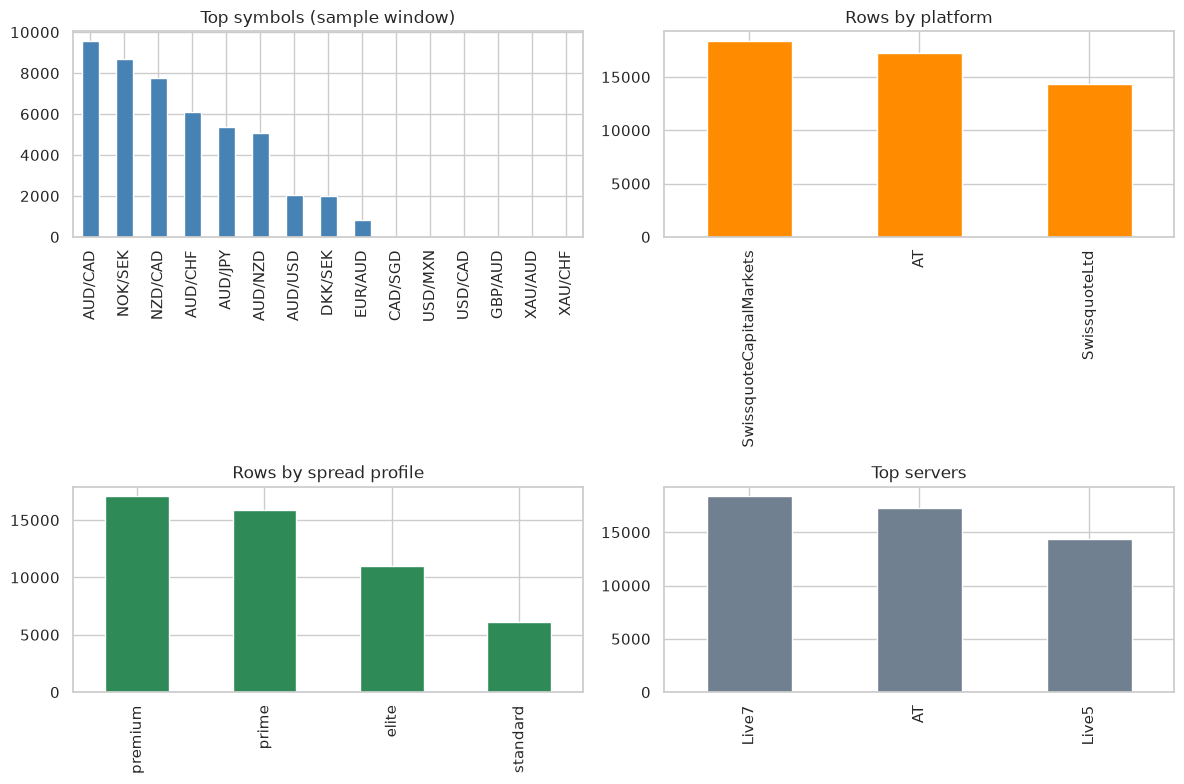

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df["symbol"].value_counts().head(15).plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Top symbols (sample window)")
axes[0, 0].set_xlabel("")

df["platform"].value_counts().plot(kind="bar", ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("Rows by platform")
axes[0, 1].set_xlabel("")

df["spread_profile"].value_counts().plot(kind="bar", ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Rows by spread profile")
axes[1, 0].set_xlabel("")

df["server"].value_counts().head(15).plot(kind="bar", ax=axes[1, 1], color="slategray")
axes[1, 1].set_title("Top servers")
axes[1, 1].set_xlabel("")

plt.tight_layout()
plt.show()


## Price & spread distributions

Sample-window shapes for mid, absolute spread, and spread in bps. Profile boxplots give a quick
cross-tier view (full day/week/history charts are in `02_spreads_eda.ipynb`).


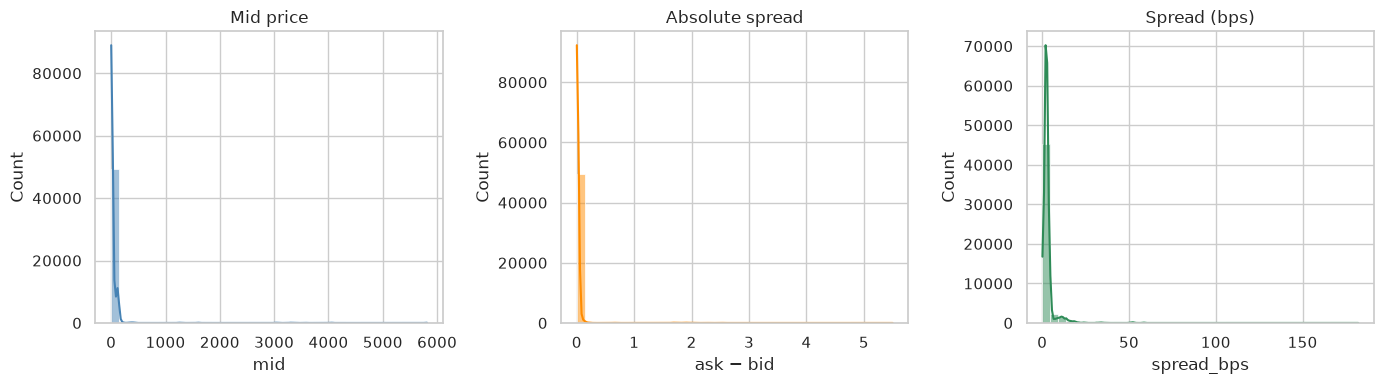

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.histplot(df["mid"], bins=40, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Mid price")
axes[0].set_xlabel("mid")

sns.histplot(df["spread_abs"], bins=40, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Absolute spread")
axes[1].set_xlabel("ask − bid")

sns.histplot(df["spread_bps"], bins=40, kde=True, ax=axes[2], color="seagreen")
axes[2].set_title("Spread (bps)")
axes[2].set_xlabel("spread_bps")

plt.tight_layout()
plt.show()


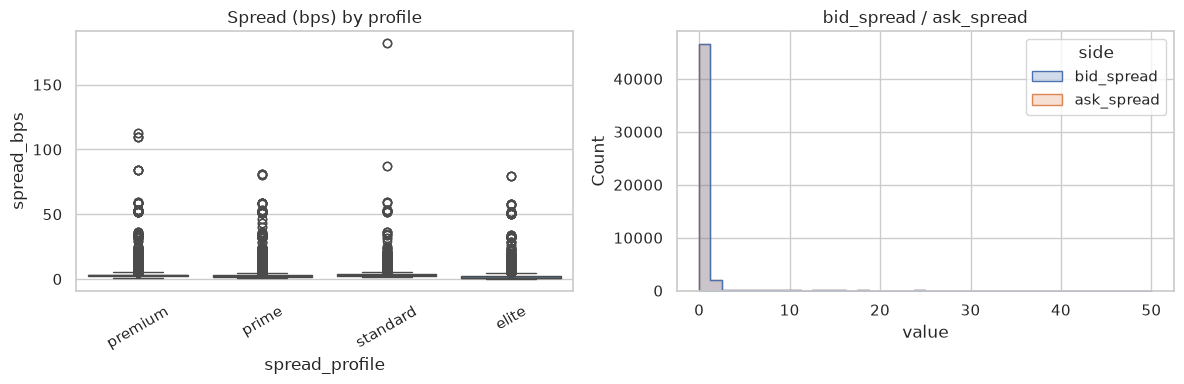

spread_abs                         spread_bps                  \
                    count    mean  median     std      count    mean  median   
spread_profile                                                                 
elite               10955  0.0214  0.0001  0.2403      10955  1.9591  0.7028   
premium             17068  0.0235  0.0003  0.2469      17068  3.6828  2.9411   
prime               15883  0.0246  0.0002  0.2540      15883  3.2423  2.2350   
standard             6094  0.0226  0.0003  0.2434       6094  3.9526  3.1984   

                        
                   std  
spread_profile          
elite           4.3265  
premium         4.6731  
prime           4.3996  
standard        5.2339

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="spread_profile", y="spread_bps", ax=axes[0], color="steelblue")
axes[0].set_title("Spread (bps) by profile")
axes[0].tick_params(axis="x", rotation=30)

if {"bid_spread", "ask_spread"}.issubset(df.columns):
    side_long = df.melt(
        value_vars=["bid_spread", "ask_spread"],
        var_name="side",
        value_name="value",
    )
    sns.histplot(data=side_long, x="value", hue="side", bins=40, element="step", ax=axes[1])
    axes[1].set_title("bid_spread / ask_spread")
    axes[1].set_xlabel("value")
else:
    axes[1].set_visible(False)

plt.tight_layout()
plt.show()

(
    df.groupby("spread_profile")[["spread_abs", "spread_bps"]]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)


## Intraday activity

Quote update rate over the sample window and a mid path for the busiest symbol (one spread profile).


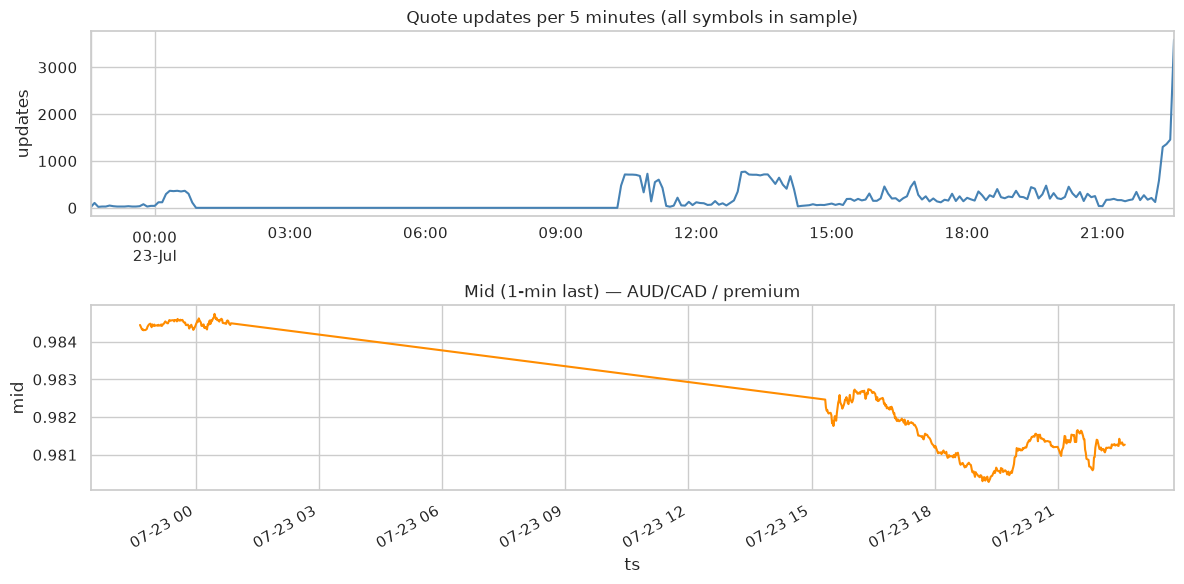

Focus: AUD/CAD @ premium (3,024 rows)
Median inter-quote gap: 0.000s


In [9]:
top_symbol = df["symbol"].value_counts().idxmax()
profile = df.loc[df["symbol"] == top_symbol, "spread_profile"].mode().iloc[0]
sym = df.loc[(df["symbol"] == top_symbol) & (df["spread_profile"] == profile)].sort_values("ts")

updates = df.set_index("ts").resample("5min").size().rename("updates")
mid_1m = sym.set_index("ts")["mid"].resample("1min").last().dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=False)

updates.plot(ax=axes[0], color="steelblue")
axes[0].set_title("Quote updates per 5 minutes (all symbols in sample)")
axes[0].set_xlabel("")
axes[0].set_ylabel("updates")

mid_1m.plot(ax=axes[1], color="darkorange")
axes[1].set_title(f"Mid (1-min last) — {top_symbol} / {profile}")
axes[1].set_xlabel("ts")
axes[1].set_ylabel("mid")

plt.tight_layout()
plt.show()

print(f"Focus: {top_symbol} @ {profile} ({len(sym):,} rows)")
print(f"Median inter-quote gap: {sym['ts'].diff().dt.total_seconds().median():.3f}s")


## Ingestion lag

Delay between quote timestamp (`ts`) and ClickHouse `ingestion_time`.


,lag_seconds
count,50000.000
mean,2.660
std,11.398
min,0.115
25%,0.782
50%,1.384
75%,2.213
max,537.314


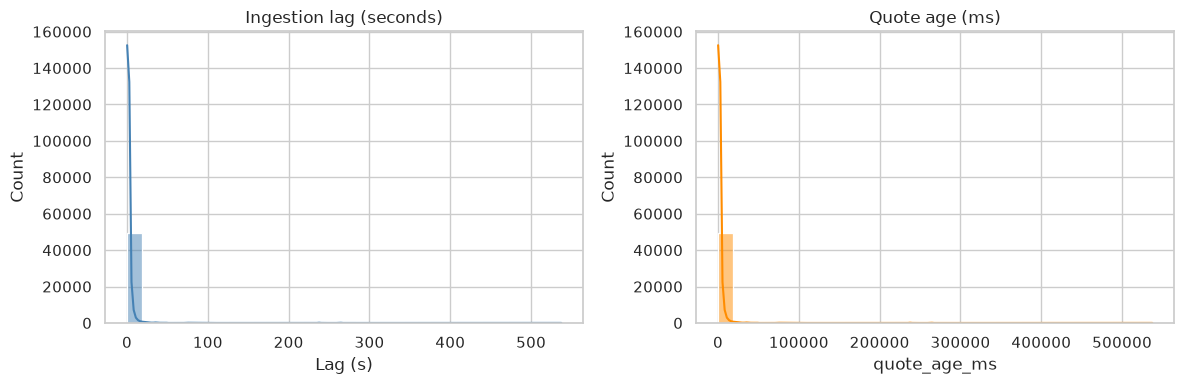

In [10]:
lag_seconds = (df["ingestion_time"] - df["ts"]).dt.total_seconds()
display(lag_seconds.describe().round(3).to_frame("lag_seconds"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(lag_seconds, bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Ingestion lag (seconds)")
axes[0].set_xlabel("Lag (s)")
axes[0].set_ylabel("Count")

if "quote_age_ms" in df.columns and df["quote_age_ms"].notna().any():
    sns.histplot(df["quote_age_ms"].dropna(), bins=30, kde=True, ax=axes[1], color="darkorange")
    axes[1].set_title("Quote age (ms)")
    axes[1].set_xlabel("quote_age_ms")
else:
    lag_by_platform = (
        pd.DataFrame({"platform": df["platform"], "lag_s": lag_seconds})
        .groupby("platform")["lag_s"]
        .median()
        .sort_values()
    )
    lag_by_platform.plot(kind="barh", ax=axes[1], color="darkorange")
    axes[1].set_title("Median ingestion lag by platform")
    axes[1].set_xlabel("Lag (s)")

plt.tight_layout()
plt.show()
